# Section 3: Outlier Detection

**Author:** Mio Diaz <br>
**Purpose:** Mid-Report 2 

The assignment asks for all of the following:

| # | Assignment item | Where in this notebook |
|---|---|---|
| a | Apply at least two outlier detection methods | §4 DBSCAN, §5 One-Class SVM |
| b | Clearly define what an "outlier" is in our project context | §2 |
| c | Visualize detected outliers and explain their characteristics | §6, §7 |
| d | Discuss potential causes (data errors, rare but valid cases, automation, ...) | §8 |
| e | Evaluate the impact of outliers on clustering and dimensionality reduction | §9 |
| — | Robustness of the definition (not required) | §10 |
| — | Feed Section 4 (integration, insights, limitations) | §11 |

**Data:** Table A (`data/merged_dataset.csv`, 62,627 repos × 49 columns), 2024 GH Archive activity only. `inactive_next_365d` (2025) is never a feature; it is only used to *check* the outliers afterwards.

## Thought process at a glance

1. **What is normal?** (§2) The full dataset is dominated by tiny one-burst repos, so "normal" there would mean "never maintained". We narrow to **real projects** (active in ≥ 3 months of 2024, 7,890 repos), where the dense middle is a consistently maintained project.
2. **What is an outlier?** (§2) *Hypothesis:* a real project far from that middle in either direction (low side = decaying, high side = abnormal volume). *Revised after §4–5:* both methods put decaying projects **inside** the normal region, because decay is common (1 in 5 real projects). Outliers are projects with **abnormal activity** (very large, automated, or an odd mix); decay is a pattern for clustering, not an anomaly.
3. **How do we measure "far"?** (§3) Log-transformed, standardized 2024 activity features, including first-half vs second-half activity so a project that went quiet looks different from a steady one.
4. **Two methods, two ideas of "far"** (§4–5): **DBSCAN** (Lesson 11, *not near any dense group*) and **One-Class SVM** (Lesson 12, *outside the learned boundary of normal*). Both are required by the assignment (≥ 2 methods); we picked two that work differently so agreement means something.
5. **Do they agree, and what kinds of outliers are there?** (§6) Overlap of the two methods, and simple rules that sort each outlier into a type (large project, activity without pushes, automation, stopped in H2, new burst).
6. **What do they look like, and why?** (§7–8) Visualize them by type, check 2025 inactivity per type, and discuss causes.
7. **Do outliers change the patterns?** (§9) Clustering and PCA with vs without outliers.
8. **Does it depend on our cutoff?** (§10) Rerun on projects active ≥ 6 months.

## 0. Dependencies on other sections

Section 3 can start on its own; only the impact on clustering / DR section depends on the other sections. To keep the three sections consistent, send the clustering and DR owners:

- **population:** repos with `active_months_2024 >= 3` (7,890 repos);
- **features:** `FEATURES` from §1 (log1p activity counts, H1 / H2 qualifying events, days since last push), then `StandardScaler`;
- coverage flags and `inactive_next_365d` are **not** features.

**Open questions:**
- [ ] Clustering: which algorithms, which `k` / `eps` / `minPts`; same population and features?
- [ ] DR: PCA components kept, t-SNE / UMAP params; same population and features?
- [ ] If the clustering owner also uses DBSCAN, agree on `eps` / `minPts` so §4 and their section don't contradict each other (their noise points = our DBSCAN outliers).
- [ ] Do they want the outlier flags exported (`is_outlier`) so they can rerun without outliers?

Until answers come back, section 9 uses a **baseline K-means + PCA** whose settings sit in one block that can be swapped for theirs.

**Notes:**

- **Notes for the report:**
  - Outlier detection, clustering and dimensionality reduction should use the same population and features, so the three sections describe the same data.
  - Finding to pass to the clustering owner (§4): decaying projects (went quiet in H2) are **not** sparse; about 1 in 5 real projects. Expect them to show up as a cluster, not as outliers.
  - Status: TODO — record teammates' answers (k, eps / minPts, PCA components) here once received.

## 1. Setup: imports, shared constants and helpers

Everything reused later lives here, so each later cell only contains the step it is about:
- **feature groups** (`VOLUME`, `BREADTH`, `TREND`, `RECENCY`) — the single source of truth for which columns are used;
- **`real_projects(df, min_months)`** — the population filter, reused for the ≥ 6-month robustness check;
- **`build_features(df)`** — log1p + fill + standardize, reused by every method and by §9–10;
- **`describe(df)`** — the descriptive statistics table;
- **`outlier_summary(...)`** / **`plot_profile(...)`** — the same summary row and profile chart for every outlier method (§4, §5, §10);
- **`style(ax)` / `save_fig(fig, name)`** — one plot style; figures go to `figures/` (SVG) and `report/img/` (PNG).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

DATA = Path("../data")
FIG_DIR = Path("../figures")
REPORT_IMG = Path("../report/img")
REPORT_IMG.mkdir(parents=True, exist_ok=True)

# Plot palette: one main hue, one highlight, recessive ink and grid.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"

# Feature groups (2024 GH Archive only). Single source of truth for every later step.
VOLUME = ["push_events_2024", "issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024",
          "review_events_2024", "release_events_2024", "stars_received_2024", "fork_events_2024"]
BREADTH = ["distinct_actors_2024", "active_days_2024", "active_months_2024"]
ENGAGEMENT = ["issue_events_2024", "issue_comment_events_2024", "pull_request_events_2024", "review_events_2024"]
TREND = ["qualifying_events_h1_2024", "qualifying_events_h2_2024"]   # separate counts: the H2/H1 ratio is undefined when H1 = 0
RECENCY = ["days_since_last_push_at_cutoff"]                         # NaN = no push in 2024 -> 366
FEATURES = VOLUME + BREADTH + TREND + RECENCY
COUNTS = VOLUME + BREADTH + TREND                                    # columns that get log1p
LABEL = "inactive_next_365d"                                         # validation only, never a feature
MIN_MONTHS = 3                                                       # "real project" cutoff (§2e)


def real_projects(df, min_months=MIN_MONTHS):
    """Repos active in at least `min_months` separate months of 2024."""
    return df[df["active_months_2024"] >= min_months].copy()


def build_features(df):
    """log1p on counts, NaN days-since-push -> 366, then standardize. Returns a DataFrame aligned to df.index."""
    raw = df[FEATURES].copy()
    raw[COUNTS] = np.log1p(raw[COUNTS])
    raw[RECENCY] = raw[RECENCY].fillna(366)
    return pd.DataFrame(StandardScaler().fit_transform(raw), index=df.index, columns=FEATURES)


def describe(df, quantiles=(0.01, 0.25, 0.5, 0.75, 0.99)):
    """Descriptive statistics: mean, chosen quantiles, max, % zero, skew."""
    t = pd.DataFrame({"mean": df.mean()})
    for q in quantiles:
        t["median" if q == 0.5 else f"p{round(q * 100)}"] = df.quantile(q)
    t["max"] = df.max()
    t["% zero"] = (df == 0).mean() * 100
    t["skew"] = df.skew()
    return t.round(2)


def style(ax, grid="y"):
    """Recessive axes: no top/right spines, light grid on one axis, muted ticks."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def title(ax, text):
    ax.set_title(text, loc="left", fontsize=10, color=INK)


def save_fig(fig, name):
    """figures/<name>.svg (no timestamp -> clean diffs) and report/img/<name>.png."""
    fig.savefig(FIG_DIR / f"{name}.svg", bbox_inches="tight", metadata={"Date": None})
    fig.savefig(REPORT_IMG / f"{name}.png", bbox_inches="tight", dpi=150)



def outlier_summary(is_out, y, quiet):
    """One row describing an outlier flag set; y (2025 label) and quiet (no H2 events) are used for validation only."""
    return {"outliers": int(is_out.sum()), "% outliers": is_out.mean() * 100,
            "inactive rate (outliers)": y[is_out].mean(), "inactive rate (inliers)": y[~is_out].mean(),
            "% of quiet projects flagged": is_out[quiet].mean() * 100}


def plot_profile(X, is_out, method, name):
    """Median standardized value of each feature, inliers vs outliers (0 = population average)."""
    prof = pd.DataFrame({"inliers": X[~is_out].median(), f"{method} outliers": X[is_out].median()})
    rows = np.arange(len(prof))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(rows + 0.2, prof.iloc[:, 0], height=0.4, color=GRID, label=prof.columns[0])
    ax.barh(rows - 0.2, prof.iloc[:, 1], height=0.4, color=BLUE, label=prof.columns[1])
    ax.set_yticks(rows, prof.index)
    ax.invert_yaxis()
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_xlabel("median standardized value (z)", color=MUTED)
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    title(ax, f"{method} outliers vs inliers: median of each feature")
    style(ax, grid="x")
    save_fig(fig, name)
    plt.show()
    return prof.round(2)


A = pd.read_csv(DATA / "merged_dataset.csv")
print(f"Table A: {len(A):,} repos x {A.shape[1]} columns | {len(FEATURES)} features")

Table A: 62,627 repos x 49 columns | 14 features


## 2. What counts as normal, and what counts as an outlier

**Question:** Before calling anything abnormal, what does a normal repo look like and is that the right reference for *maintained*?

**Approach:**
- 2a–2c: describe the **full population** and show why it can't be the reference.
- 2d: decide where a **real project** starts (active months).
- 2e: describe the **real-project population**; its dense middle is *normal*.
- 2f: write the definition.

### 2a. The full population: descriptive statistics

**Background for readers new to open source and GitHub:**

- **GitHub** is a website where software projects are stored and developed in public. Each project lives in a **repository ("repo")**: a folder of code plus its history.
- **Open source** means the code is public, and anyone can read it, report problems, or propose changes. A project is **maintained** when someone keeps working on it: fixing bugs, answering questions, publishing new versions.
- GitHub records every action on a public repo as an **event**: uploading code, opening an issue, leaving a comment, and so on. **GH Archive** is a public dataset of all these events. We counted each repo's events over calendar year **2024**.
- **What is being analyzed:** one row per repo (**62,627 repos**), with counts of what happened to it in 2024. The table below summarizes each of these counts across all repos.

**How to read the columns** (each row is one feature, measured over all 62,627 repos):

| Column | Meaning |
|---|---|
| **mean** | The average. A few huge repos pull it up. |
| **50%** (median) | The middle repo: half are below, half above. This is the *typical* repo. |
| **75% / 90% / 99%** | Percentiles: 75%, 90% or 99% of repos are at or below this value. The 99% value is where the top 1% begins. |
| **max** | The single largest repo. |
| **% zero** | Share of repos with exactly 0 for this feature. |
| **skew** | How lopsided the distribution is. 0 = symmetric; above about 1 = a long right tail (a few very large values); above 10 = extremely lopsided. |

**Key comparison: mean vs median.** If the mean is much larger than the median, a small number of giant repos are pulling the average up, and the "average repo" does not describe any real repo.

In [2]:
describe(A[VOLUME + BREADTH + RECENCY], quantiles=(0.5, 0.75, 0.9, 0.99))

,mean,median,p75,p90,p99,max,% zero,skew
push_events_2024,43.77,3.0,14.0,35.0,301.00,362071.0,1.91,136.80
issue_events_2024,1.61,0.0,0.0,0.0,13.00,51240.0,95.41,248.46
issue_comment_events_2024,2.41,0.0,0.0,0.0,27.00,30312.0,93.83,216.38
pull_request_events_2024,3.60,0.0,0.0,2.0,67.00,6209.0,84.62,69.51
review_events_2024,2.08,0.0,0.0,0.0,15.74,9237.0,97.23,79.89
release_events_2024,0.25,0.0,0.0,0.0,4.00,361.0,97.09,45.88
stars_received_2024,1.84,0.0,0.0,0.0,12.00,8745.0,90.41,96.29
fork_events_2024,0.40,0.0,0.0,0.0,4.00,1653.0,94.88,90.32
distinct_actors_2024,1.54,1.0,1.0,2.0,7.00,1251.0,0.00,86.88
active_days_2024,6.82,1.0,4.0,12.0,103.00,366.0,0.00,9.81


**Notes:**

- **What it shows, row by row:**

**Volume rows: how much happened**

- **`push_events_2024`**: a *push* is uploading new code (commits) to the repo. The most basic sign that someone is working on it.
  - Median **3**: the typical repo received 3 uploads in all of 2024.
  - Mean **43.77**, about 15× the median, because a few repos push constantly.
  - 75% = 14, 90% = 35, 99% = 301: 90% of repos pushed 35 times or fewer; only the top 1% pushed more than 301 times.
  - Max **362,071** (`sslam1234/statslamgamedata`): about 1,000 pushes per day. No person works like that, so this is an automated script.
  - % zero **1.91%** (1,198 repos): no pushes at all. They are in the data because they had other events (e.g. comments).
  - Skew **136.8**: extremely lopsided.
  - **Takeaway:** most repos are small; a tiny number are enormous.

**Engagement rows: people interacting with the project.** These are how users and contributors communicate with a project.

- **`issue_events_2024`**: an *issue* is a public ticket for a bug report, question or feature request; events are opening, closing or reopening one.
  - Median 0 and **95.4% zero**: 19 out of 20 repos had no issue activity at all.
  - 99% = 13: even the top 1% starts at just 13 issue events.
  - Max **51,240** (`adguardteam/adguardfilters`, a large community-maintained ad-blocking filter list that uses issues as a ticket queue).
- **`issue_comment_events_2024`**: comments written on issues or pull requests (discussion).
  - **93.8% zero**, 99% = 27, max **30,312** (again `adguardteam/adguardfilters`).
- **`pull_request_events_2024`**: a *pull request (PR)* is a proposed code change submitted for the maintainers to review and accept ("merge"); events are opening, closing or merging one.
  - **84.6% zero**, the *least* rare engagement type. 90% = 2, so the top 10% has at least a couple of PR events.
  - Max 6,209 (`navikt/pensjon-etterlatte-saksbehandling`, a Norwegian government team's repo).
  - PRs are the most common form of collaboration, but still uncommon.
- **`review_events_2024`**: a *review* is someone reading a PR and approving it or requesting changes.
  - **97.2% zero.** A review needs a second person, so it is rarer than a PR.
  - 99% = 15.74: the decimal appears because percentiles interpolate between two repos. Read it as "about 16".
  - Max 9,237 (same `navikt` repo).
- **Takeaway:** a repo with *any* community activity is already unusual in the full dataset.

**Release, stars and forks: signs that other people use the project**

- **`release_events_2024`**: a *release* is a formally published, numbered version (e.g. v1.2.0) that users can download.
  - **97.1% zero**, 99% = 4, max 361. Formal releases are what maintained libraries and tools do; almost no repo does them.
- **`stars_received_2024`**: a *star* is a GitHub "like"/bookmark; new stars measure attention.
  - **90.4% zero**, 99% = 12, max **8,745** (`lukasz-madon/awesome-remote-job`, a popular curated list). Nine in ten repos got no new attention in 2024.
- **`fork_events_2024`**: a *fork* is someone copying the repo to their own account to modify or build on it.
  - **94.9% zero**, 99% = 4, max 1,653 (`argoproj/argocd-example-apps`, an example repo people copy as a starting point).
- **Takeaway:** these "people use this" signals are absent for almost every repo.

**Breadth rows: how many people, and how spread out over time**

- **`distinct_actors_2024`**: number of different GitHub accounts that did anything to the repo. Automated accounts (bots) count too.
  - Median 1, 75% = 1, 90% = 2: **most repos are a one-person effort.**
  - 0% zero by construction: a repo needs at least one actor to appear in the data.
  - 99% = 7, max **1,251** (`adguardteam/adguardfilters`).
- **`active_days_2024`**: number of days in 2024 with at least one event.
  - Median **1**: the typical repo was touched on **one single day**.
  - 90% = 12, 99% = 103, max **366** (2024 was a leap year). 75 repos were active every day; these are mostly automated (bots, scrapers, auto-updated profile pages).
- **`active_months_2024`**: number of months (1–12) with at least one event.
  - Median 1, 75% = 1: **three quarters of repos were active in only one month.**
  - 90% = 3: only about the top 10% reach 3 or more months. This is why the 3-month "real project" cutoff (§2d) keeps 7,890 repos (12.6%).
  - Skew 3.79: much less extreme than the counts, because the value cannot exceed 12 (734 repos reach 12).

**Recency row: how long ago the last upload was**

- **`days_since_last_push_at_cutoff`**: days between the repo's last push and the cutoff date, **January 1, 2025**.
  - Median **90**: the typical repo was last pushed around early October 2024.
  - 75% = 148, 90% = 193, max 366 (last push on January 1, 2024, the first day of the window).
  - Skew **0.96**: the only roughly symmetric feature. It is measured in days (bounded 0–366), not counts, so it is not log-transformed.
  - **Caveat:** the 1,198 repos with no push (1.9%) have no value here and are skipped by `describe()`, so these statistics cover only repos that pushed at least once. In the feature matrix (§3) they are filled with 366 = "no push in the whole window".

### **Notes for the report:**
  1. **The median repo is tiny:** 3 pushes, 1 person, 1 active day, 1 active month, no community activity.
  2. **Every count is extremely skewed** (skew 46 to 248 for the volume rows) and the mean sits far above the median. This is why all counts are log-transformed.
  3. **Community signals are rare:** issues, comments, PRs, reviews, releases, stars and forks are each zero for 84–97% of repos.
  4. Therefore the full dataset cannot serve as the reference for a *maintained* project: in it, a tiny one-burst repo is "normal" and every maintained project would look like an outlier. This motivates narrowing the population to real projects.

### 2b. The typical repo profile

**What this chart is:** each bar is a yes/no condition that describes a "tiny" repo (for example, "only one person ever touched it"). The bar length is the **share of all 62,627 repos** that meet the condition. The orange bar at the top is the strictest test: repos that meet **all three** of: one person, one month, no community activity.

**Terms:** a *contributor (distinct actor)* is any GitHub account that did something to the repo. *Community activity* = issues, comments, pull requests or reviews (defined in §2a). *H1* = January–June 2024, *H2* = July–December 2024.

**Why we look at it:** to decide what "normal" means, we first check what the most common repo looks like. If most repos are tiny, then "normal" in the full dataset means tiny.

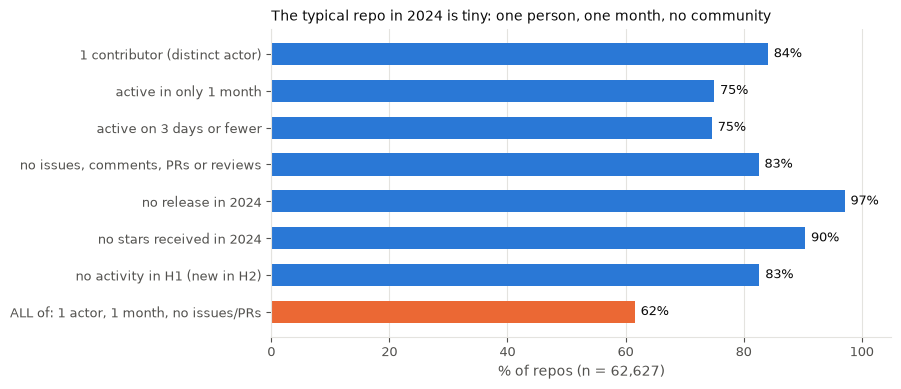

In [3]:
no_engagement = A[ENGAGEMENT].sum(axis=1).eq(0)
one_actor, one_month = A["distinct_actors_2024"].eq(1), A["active_months_2024"].eq(1)
profile = pd.Series({
    "1 contributor (distinct actor)": one_actor.mean(),
    "active in only 1 month": one_month.mean(),
    "active on 3 days or fewer": A["active_days_2024"].le(3).mean(),
    "no issues, comments, PRs or reviews": no_engagement.mean(),
    "no release in 2024": A["release_events_2024"].eq(0).mean(),
    "no stars received in 2024": A["stars_received_2024"].eq(0).mean(),
    "no activity in H1 (new in H2)": A["h1_qualifying_events_zero"].eq(1).mean(),
    "ALL of: 1 actor, 1 month, no issues/PRs": (one_actor & one_month & no_engagement).mean(),
}).mul(100)[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(profile.index, profile.values, color=[ORANGE] + [BLUE] * (len(profile) - 1), height=0.6)
for y, v in enumerate(profile.values):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9, color=INK)
ax.set(xlim=(0, 105))
ax.set_xlabel(f"% of repos (n = {len(A):,})", color=MUTED)
title(ax, "The typical repo in 2024 is tiny: one person, one month, no community")
style(ax, grid="x")
save_fig(fig, "outliers_normal_profile")
plt.show()

**Notes:**
- **What it shows, bar by bar** (% of all 62,627 repos):
  - **1 contributor: 84%.** More than 4 in 5 repos were touched by only one account in 2024: a personal project, not a team effort.
  - **Active in only 1 month: 75%.** Three quarters of repos had activity in a single calendar month and nothing in the other eleven.
  - **Active on 3 days or fewer: 75%.** The same three quarters were worked on for at most three days in the whole year: a short burst, then nothing.
  - **No issues, comments, PRs or reviews: 82.5%.** Four in five repos had no community interaction at all: nobody reported a problem, discussed anything, or proposed a change.
  - **No release in 2024: 97%.** Almost no repo published a formal version for others to download.
  - **No stars received in 2024: 90%.** Nine in ten repos got no new "likes"/bookmarks, so almost nobody noticed them.
  - **No activity in H1 (new in H2): 83%.** Most repos only started doing anything in the second half of 2024. Many are new repos created in H2, so they have no H1 history at all.
  - **ALL of: 1 actor, 1 month, no issues/PRs (orange): 62%.** The majority of repos are a single person working for a single month with no one else involved.

### **Notes for the report:**
  - The typical GitHub repo is a short, solo burst: a homework assignment, an experiment, a personal backup. It is not a maintained software project.
  - If we used the full dataset as the reference, this tiny burst would be "normal", and every maintained project (many people, many months, releases) would look like an outlier. That is the opposite of what we want, so the reference must be narrowed.

### 2c. Why everything is log-transformed

**What this chart is:** two histograms of the **same** data, the number of pushes (code uploads) per repo in 2024. A histogram splits the values into bins and shows how many repos fall in each bin.

- **Left (raw counts):** the plain numbers. The y-axis is on a log scale so that small bars are visible at all.
- **Right (`log1p`):** the same numbers after the transform `log1p(x) = log(1 + x)`. The "+1" keeps repos with 0 pushes at 0 (log of 0 is undefined). Each step of +1 on this axis means about 2.7× more pushes, so it compares repos by *ratio* (10 vs 100 is the same gap as 100 vs 1,000) instead of by raw difference.

**Why we look at it:** distance-based outlier methods (DBSCAN, One-Class SVM) measure how far apart repos are. On raw counts, one repo with 362,071 pushes would dominate every distance, and the methods would simply rank repos by size.

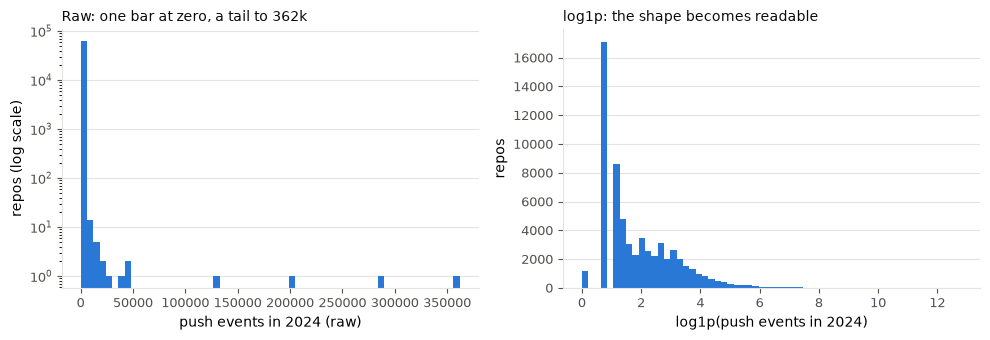

In [4]:
x = A["push_events_2024"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, values, xlabel, ylog, text in [
    (axes[0], x, "push events in 2024 (raw)", True, "Raw: one bar at zero, a tail to 362k"),
    (axes[1], np.log1p(x), "log1p(push events in 2024)", False, "log1p: the shape becomes readable"),
]:
    ax.hist(values, bins=60, color=BLUE)
    ax.set(xlabel=xlabel, ylabel="repos (log scale)" if ylog else "repos", yscale="log" if ylog else "linear")
    title(ax, text)
    style(ax)
fig.tight_layout()
save_fig(fig, "outliers_push_raw_vs_log")
plt.show()

**Notes:**
- **What it shows:**
  - **Left, raw:** the first bar (0 to about 6,000 pushes) holds **62,598 of 62,627 repos (99.95%)**. Everything else is a thin tail stretching out to 362,071. You cannot see any difference between a repo with 3 pushes and one with 3,000: both sit in the same bar.
  - **Right, `log1p`:** the same repos now spread out over 0 to 12.8. The peak is on the left (0–2.5 ≈ 0–11 pushes, where 71% of repos sit; the median of 3 pushes is at 1.39), and the curve falls off smoothly to the right. Large repos are still clearly on the right, but no longer infinitely far away.

### **Notes for the report:**
  - All count features are log-transformed (`log1p`) and then standardized (mean 0, standard deviation 1) before any method is applied.
  - Without the log, "outlier" would just mean "biggest repo". With it, a repo is an outlier only if it is unusual relative to others *in proportion*, and an unusual *combination* of features can be detected (e.g. many pushes but no community at all).
  - Days since last push is not log-transformed: it is a bounded number of days (0–366) and is already roughly symmetric.

### 2d. Where a "real project" starts

**What this chart is:** repos grouped by how many of the 12 months of 2024 they were active in (x-axis, 1–12).

- **Left:** how many repos are in each group. The y-axis is a log scale (each gridline is 10× the one below), because the 1-month group is huge.
- **Right:** the share of each group that was **inactive in 2025**.
- Blue bars = kept as "real projects" (≥ 3 months); grey = excluded. The orange dashed line marks the cutoff.

**The 2025 label (`inactive_next_365d`):** 1 if the repo had **no maintenance activity at all** (no push, issue, comment, PR, review or release) in the 365 days after January 1, 2025. It is our signal that a project was abandoned. It is **never used to detect outliers**, only to describe and check results afterwards.

**Why this cutoff:** the cutoff is set on domain grounds: "someone came back to it in at least 3 separate months" is the minimum for something to count as being *maintained* rather than a one-off. The label is only shown to describe the groups, not to tune the cutoff.

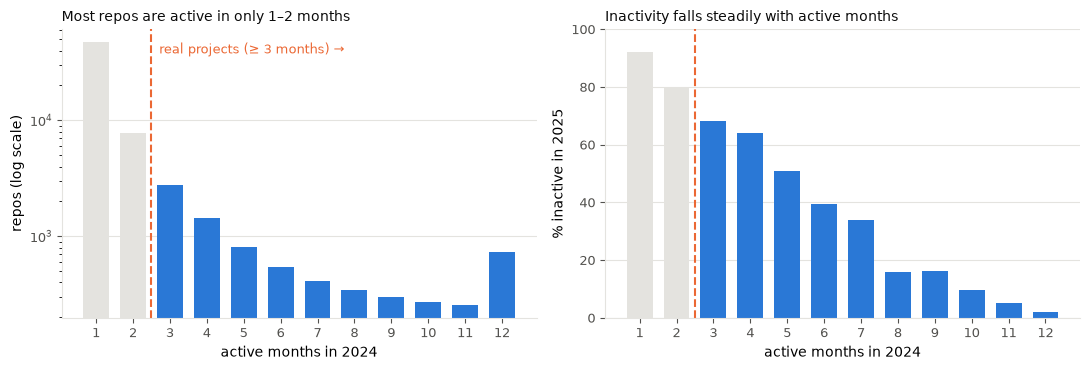

active_months_2024,1,2,3,4,5,6,7,8,9,10,11,12
repos,46973.00,7764.0,2775.00,1453.00,807.00,540.0,408.00,348.00,297.00,271.0,257.00,734.00
inactive_rate,0.92,0.8,0.68,0.64,0.51,0.4,0.34,0.16,0.16,0.1,0.05,0.02


In [5]:
by_month = A.groupby("active_months_2024")[LABEL].agg(repos="size", inactive_rate="mean")
months = by_month.index.to_numpy()
colors = np.where(months >= MIN_MONTHS, BLUE, GRID)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, values, ylabel, text in [
    (axes[0], by_month["repos"], "repos (log scale)", "Most repos are active in only 1–2 months"),
    (axes[1], by_month["inactive_rate"] * 100, "% inactive in 2025", "Inactivity falls steadily with active months"),
]:
    ax.bar(months, values, color=colors, width=0.7)
    ax.set(xlabel="active months in 2024", ylabel=ylabel, xticks=months)
    ax.axvline(MIN_MONTHS - 0.5, color=ORANGE, linestyle="--", linewidth=1.5)
    title(ax, text)
    style(ax)
axes[0].set_yscale("log")
axes[1].set_ylim(0, 100)
axes[0].text(MIN_MONTHS - 0.4, by_month["repos"].max(), f" real projects (≥ {MIN_MONTHS} months) →", color=ORANGE, fontsize=9, va="top")
fig.tight_layout()
save_fig(fig, "outliers_population_cutoff")
plt.show()
by_month.round(2).T

**Notes:**

- **What it shows, group by group** (repos; % inactive in 2025):
  - **1 month: 46,973 repos; 92% inactive.** The largest group by far. Almost all of them were never touched again.
  - **2 months: 7,764; 80%.** Still mostly abandoned.
  - **3 months: 2,775; 68%** ← first group kept as a real project. From here on, someone kept coming back.
  - **4 months: 1,453; 64%** and **5 months: 807; 51%.** About half of these projects are abandoned.
  - **6 months: 540; 40%** and **7 months: 408; 34%.** Half a year of activity: most survive.
  - **8–9 months: 348 and 297; 16%.** A clear drop: projects active most of the year rarely stop.
  - **10 months: 271; 10%** and **11 months: 257; 5%.**
  - **12 months: 734; 2%.** Active every month. This group is *bigger* than 9, 10 or 11 months: it contains genuinely busy projects plus always-on automation (bots, scheduled scripts), which is the first hint of high-side outliers.

### **Notes for the report:**
  - The more months a repo was active in 2024, the less likely it went inactive in 2025: from 92% at 1 month down to 2% at 12 months, almost without exception.
  - Repos active in 1–2 months (87% of the dataset) are one-off bursts; they were never maintained, so they cannot be "unmaintained outliers". They are reported separately and excluded.
  - The cutoff of 3 months is a domain choice, not tuned on the label. ≥ 6 months is used in §10 to check that results do not depend on this choice.

### 2e. The real-project population

**What this is:**

1. **Population split table:** every repo is put into one of three groups by active months. Columns: number of repos, the share inactive in 2025 (0.90 = 90%), and the group's share of all repos.
2. **Descriptive statistics for real projects only** (7,890 repos), with the same columns as §2a plus **p1** (1% of repos are at or below this) and **p25** (25% are at or below this). Two new rows appear:
   - **`qualifying_events_h1_2024` / `qualifying_events_h2_2024`**: number of *maintenance* events (pushes, issues, comments, PRs, reviews, releases; stars and forks are not counted) in H1 (January–June) and H2 (July–December) 2024. Comparing the two halves shows whether a project is speeding up or slowing down.
3. **Tails chart:** histograms of three key features for real projects. Solid black line = median (typical project); dotted orange = p1 (the lowest 1%); dashed orange = p99 (the highest 1%). The region beyond each orange line is a *tail*, where outliers would be.

**Why we look at it:** here, the middle of the distribution should be a consistently maintained project, and we check that both tails (very quiet and very busy) exist.

In [6]:
P = real_projects(A)
group = np.select([A["active_months_2024"] >= 6, A["active_months_2024"] >= MIN_MONTHS],
                  ["real project, ≥ 6 months (robustness set, §10)", "real project, 3–5 months"],
                  default="one-burst repo, 1–2 months (excluded)")
split = A.groupby(group)[LABEL].agg(repos="size", inactive_rate="mean")
split["% of repos"] = split["repos"] / len(A) * 100
display(split.round(2))
print(f"Real-project population P: {len(P):,} repos ({len(P) / len(A):.1%}), inactive rate {P[LABEL].mean():.2f}")
describe(P[FEATURES])

,repos,inactive_rate,% of repos
"one-burst repo, 1–2 months (excluded)",54737,0.90,87.40
"real project, 3–5 months",5035,0.64,8.04
"real project, ≥ 6 months (robustness set, §10)",2855,0.18,4.56


Real-project population P: 7,890 repos (12.6%), inactive rate 0.47


,mean,p1,p25,median,p75,p99,max,% zero,skew
push_events_2024,214.05,0.89,19.0,37.0,83.00,1781.44,362071.0,1.00,71.93
issue_events_2024,11.74,0.00,0.0,0.0,0.00,111.33,51240.0,81.90,88.22
issue_comment_events_2024,18.09,0.00,0.0,0.0,1.00,289.11,30312.0,72.86,77.06
pull_request_events_2024,22.78,0.00,0.0,0.0,10.00,385.55,6209.0,59.10,25.84
review_events_2024,15.40,0.00,0.0,0.0,0.00,276.11,9237.0,86.89,28.77
release_events_2024,1.62,0.00,0.0,0.0,0.00,28.00,361.0,88.95,16.93
stars_received_2024,12.68,0.00,0.0,0.0,1.00,233.11,8745.0,71.80,34.80
fork_events_2024,2.54,0.00,0.0,0.0,0.00,45.00,1653.0,81.10,34.71
distinct_actors_2024,4.08,1.00,1.0,1.0,2.75,44.00,1251.0,0.00,31.53
active_days_2024,38.37,3.00,9.0,17.0,34.00,365.00,366.0,0.00,3.53


**Notes:**

- **What the split table shows:**
  - **One-burst repos, 1–2 months: 54,737 repos (87.4%), 90% inactive in 2025.** Excluded from outlier detection.
  - **Real projects, 3–5 months: 5,035 (8.0%), 64% inactive.**
  - **Real projects, ≥ 6 months: 2,855 (4.6%), 18% inactive.** Also used as a stricter population in §10.
  - Together, real projects = **7,890 repos (12.6%), 47% inactive.** That is roughly a coin flip, so this group contains both projects that last and projects that are decaying, which is exactly the mix we want to study.
- **What the statistics table shows, row by row** (real projects vs the full population in §2a):
  - **`push_events_2024`:** median **37** (vs 3), p25 = 19, p75 = 83, p99 ≈ 1,781, max still 362,071. Only 1% have no pushes. The typical real project gets about 3 uploads a month.
  - **`issue_events_2024`:** still **82% zero** (vs 95%), but p99 = 111. Most real projects do not use issues, but the top ones use them heavily.
  - **`issue_comment_events_2024`:** 73% zero; p75 = 1; p99 ≈ 289.
  - **`pull_request_events_2024`:** **59% zero** (vs 85%); p75 = 10. PRs are the most common community activity: 4 in 10 real projects receive proposed changes.
  - **`review_events_2024`:** 87% zero; p99 ≈ 276.
  - **`release_events_2024`:** 89% zero; p99 = 28. Formal versions are still rare.
  - **`stars_received_2024`:** 72% zero; p75 = 1; p99 ≈ 233.
  - **`fork_events_2024`:** 81% zero; p99 = 45.
  - **`distinct_actors_2024`:** median **1**, p75 ≈ 3, p99 = 44. 56% of real projects still have one contributor: "maintained" here usually means **one person who keeps coming back**, not a team.
  - **`active_days_2024`:** p1 = 3 (the minimum possible with 3 active months), median **17**, p75 = 34, p99 = 365. The typical real project is worked on about 1–2 days per month.
  - **`active_months_2024`:** p25 = 3, median 4, p75 = 7. Skew 1.02: fairly balanced.
  - **`qualifying_events_h1_2024`:** median 26; **29% zero**, i.e. new projects that started in H2.
  - **`qualifying_events_h2_2024`:** median 15; **19% zero** = **1,497 projects that went quiet** (had activity earlier in the year, then nothing from July to December). The mean (162) is higher than in H1 because of a few huge automated repos (max 311,718), while the median *drops* from 26 to 15: the typical project slowed down in the second half.
  - **`days_since_last_push_at_cutoff`:** p25 = 16, median **58**, p75 = 164, p99 = 302. The typical real project was last pushed about two months before the cutoff (vs three months for all repos). Skew 0.80: roughly symmetric. 79 projects with no push are not included here.
  - **Skew** is still high for the counts (17 to 88), so the log transform is still needed.
- **What the tails chart shows:**
  - **Days since last push (left):** median 58 days; the dotted p1 line is at 1 day (pushed on the last day of the year), and the dashed p99 line is at about 363 days. The right tail is the **low-activity side**: projects that stopped pushing early in 2024.
  - **H2 maintenance events (middle, `log1p` scale):** p1 = 0, median = 15, p99 ≈ 1,381. The tall bar at 0 is the 1,497 projects that went quiet: a large group, not a thin tail.
  - **Pushes (right, `log1p` scale):** p1 ≈ 1, median 37, p99 ≈ 1,781. The far right is the **high-activity side**: bulk or automated pushers.

### **Notes for the report:**
  - Inside real projects, the middle is a **solo maintainer who keeps coming back**: about 37 pushes, 17 active days spread over 4 months, last push about 2 months before the cutoff.
  - Both tails exist: a low side (projects that went quiet in H2, 19%) and a high side (bulk and automated activity, up to 362,071 pushes).
  - The low side is *large*: about 1 in 5 projects. This already hints at the finding that decay is too common to count as an outlier.

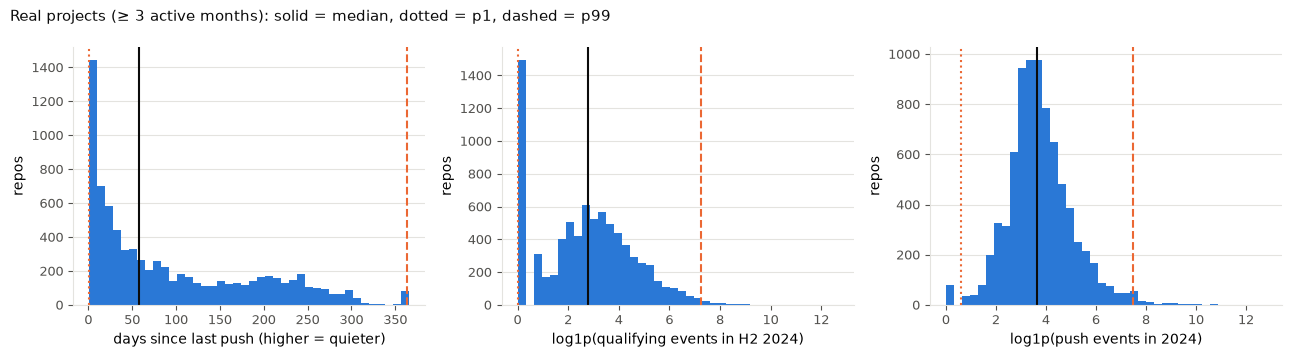

In [32]:
# Both tails inside the real-project population: low side (went quiet) and high side (huge volume).
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, xlabel in [
    (axes[0], "days_since_last_push_at_cutoff", "days since last push (higher = quieter)"),
    (axes[1], "qualifying_events_h2_2024", "log1p(qualifying events in H2 2024)"),
    (axes[2], "push_events_2024", "log1p(push events in 2024)"),
]:
    v = P[col].fillna(366)
    v = v if col in RECENCY else np.log1p(v)
    ax.hist(v, bins=40, color=BLUE)
    for q, ls, color in [(0.01, ":", ORANGE), (0.5, "-", INK), (0.99, "--", ORANGE)]:
        ax.axvline(v.quantile(q), color=color, linestyle=ls, linewidth=1.5)
    ax.set(xlabel=xlabel, ylabel="repos")
    style(ax)
fig.suptitle(f"Real projects (≥ {MIN_MONTHS} active months): solid = median, dotted = p1, dashed = p99",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
save_fig(fig, "outliers_project_tails")
plt.show()

### 2f. Definition

**Terms used below:**

- **Outlier:** a data point (here, a repo) that is very different from most others.
- **DBSCAN** (§4) and **One-Class SVM** (§5) are the two outlier detection methods used. Both learn where "normal" repos sit and flag the ones far from that region.
- **Went quiet in H2:** had activity in January–June 2024, then no maintenance activity in July–December.
- **Global outlier:** unusual compared with the whole dataset. **Collective outlier:** a group of repos that look normal one by one, but are unusual as a group (e.g. many identical repos created by one script). (Lesson 11.2)
- **Lorem ipsum:** standard placeholder text ("lorem ipsum dolor sit amet…"); repo names made of it are a sign of auto-generated repos.

**Initial hypothesis (before running any method):**

> Within real projects (≥ 3 active months in 2024), an outlier is a repo whose 2024 activity profile is far from the consistently-maintained middle, on the log scale, in either direction: **low side** = decaying (active, then went quiet), **high side** = abnormal volume (automation, bots, mirrors, very large projects).

**What the methods showed (§4–5):** DBSCAN and One-Class SVM both put the projects that went quiet in H2 **inside** the normal region (0.9% and 1.5% of them flagged), and their outliers go inactive in 2025 *less* often than the population (20% and 28% vs 47%). Decay is too common to be an outlier: about **1 in 5** real projects went quiet in H2.

**Revised definition (used from §6 on):**

> **Within real projects, an outlier is a repo whose 2024 activity is abnormal compared with a consistently maintained project: unusually large, automated, or an unusual mix of activity. Decay is not an outlier in this data; it is a common pattern, which clustering is better placed to describe.**

- **Types (Lesson 11.2):** mostly **global** outliers (very large projects, bulk automation); **collective** outliers also appear (farms of generated repos with lorem-ipsum names, many near-identical classroom repos).
- **Expected share:** about 1–2% (One-Class SVM `nu = 0.01`; DBSCAN's share follows from `eps`).
- **Validation (not used for detection):** 2025 inactivity by outlier type (§6). Only the small "stopped in H2" type should look like decay.

**Notes:**

- **Assignment item:** Outlier Detection → clearly define what constitutes an outlier in your project context
- **What it shows:**
  - **Full population (2a–2c):** the median repo in 2024 has 3 pushes, 1 contributor, 1 active day and 1 active month, and no issues, PRs, reviews, releases or stars. 84% have a single contributor, 75% were active in only one month, 62% match *all* of: 1 actor, 1 month, no issues/PRs. Counts are extremely right-skewed (skew 46–248; pushes: mean 43.8, median 3, p99 301, max 362,071).
  - **Population cutoff (2d):** 2025 inactivity falls steadily with active months: 92% at 1 month, 68% at 3, 40% at 6, 2% at 12.
  - **Real projects (2e):** 7,890 repos (12.6%) with ≥ 3 active months; 47% went inactive in 2025 (vs 90% for one-burst repos and 18% for ≥ 6 months).
  - The median real project: 37 pushes, 4 active months, 17 active days, 26 qualifying events in H1 and 15 in H2, last push 58 days before the cutoff. Still usually **one contributor** (median 1, p75 ≈ 3): "maintained" here mostly means a solo maintainer who keeps coming back.
  - Both tails exist: p1 of pushes is ~1 and 19% of projects had **no** qualifying events in H2 (low side), while p99 of pushes is ~1,780 against a max of 362,071 (high side).
  - **Automation already visible:** 98 repos were active on 360+ days of 2024, 62% with a single contributor and a median of ~1,500 pushes. Names are mostly profile READMEs (`owner/owner`, auto-updated daily by GitHub Actions), scrapers (`cv-arxiv-daily`, `v2free`) and bots (`tiktokbot`): activity without maintenance, i.e. the high-side outlier type.
- **Notes for the report:**
  - Using the full population would make a tiny one-burst repo "normal" and every maintained project an outlier, which is the opposite of what this project needs. So outliers are detected among real projects, and the one-burst repos (87%) are reported as a separate, never-maintained group.
  - *Normal* = a consistently maintained project.
  - **Hypothesis:** outliers are far from normal in either direction (low side = decaying, high side = abnormal volume).
  - **Revised after testing (§4–5):** both methods treat decaying projects as normal, because decay is common (1 in 5 real projects). Outliers are projects with **abnormal activity**: very large, automated, or an odd mix of activity. Decay is a pattern of the data, better found by clustering. Report both the hypothesis and the revision: it shows the definition was tested, not assumed.
  - The 2025 label is never used to detect outliers, only to check them afterwards.
  - The log transform is required: on raw counts every method would just rank repos by size.


## 3. Feature matrix

**Question:** How do we turn each real project into a point, so that "far from normal" can be measured?

**Approach:**
- Population `P` from §2 (7,890 repos).
- `build_features` from §1: `log1p` on counts (§2c), days since last push with NaN → 366, `StandardScaler` so no feature dominates by its units.
- **H1 and H2 events as separate features**, so a project that went quiet (high H1, low H2) is far from a steady one even with the same yearly total.
- **Not features:** identifiers; deps.dev / Scorecard values (98–100% missing); coverage flags like `has_package` (a rare 1 would standardize to z ≈ 8 and dominate distances); the 2025 label.

In [8]:
X = build_features(P)
y = P[LABEL]                                   # validation only
quiet = P["qualifying_events_h2_2024"].eq(0)  # 'went quiet': no qualifying events in H2 2024 (validation only)

assert not X.isna().any().any(), "NaN in feature matrix"
assert LABEL not in X.columns and "has_package" not in X.columns
print(f"X: {X.shape[0]:,} real projects x {X.shape[1]} features | went quiet in H2: {quiet.sum():,} ({quiet.mean():.0%})")
X.describe().loc[["mean", "std", "min", "max"]].round(2)

X: 7,890 real projects x 14 features | went quiet in H2: 1,497 (19%)


,push_events_2024,issue_events_2024,issue_comment_events_2024,pull_request_events_2024,review_events_2024,release_events_2024,stars_received_2024,fork_events_2024,distinct_actors_2024,active_days_2024,active_months_2024,qualifying_events_h1_2024,qualifying_events_h2_2024,days_since_last_push_at_cutoff
mean,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.86,-0.40,-0.50,-0.71,-0.33,-0.30,-0.45,-0.38,-0.60,-1.66,-0.99,-1.40,-1.42,-1.02
max,6.92,9.99,7.05,4.52,7.46,8.17,7.66,9.43,8.99,2.86,1.87,3.93,5.24,2.90


**Notes:**

- **Assignment item:** Outlier Detection → data used for detection; population filter; excluded columns and why
- **What it shows:**
  - Feature matrix `X`: **7,890 real projects × 14 features**, all from 2024 GH Archive activity, standardized (mean 0, SD 1). No missing values.
  - Feature groups: volume (8: pushes, issues, issue comments, PRs, reviews, releases, stars, forks), breadth (3: distinct actors, active days, active months), trend (2: qualifying events in H1 and in H2), recency (1: days since last push).
  - Transformations: `log1p` on all counts; days since last push missing for 79 projects with no push → 366 ("no push in the window"); then `StandardScaler`.
- **Notes for the report:**
  - Each real project becomes a point in a 14-dimensional space, so "far from normal" can be measured as distance (DBSCAN) or as being outside a learned boundary (One-Class SVM).
  - Counts are log-transformed because they are extremely skewed (§2c); without it, every method would just pick the biggest repos.
  - First-half and second-half activity are separate features, so a project that went quiet (high H1, low H2) is far from a steady one even with the same yearly total. The H2/H1 ratio was not used because it is undefined for the 29% of projects that started in H2.
  - Left out on purpose: deps.dev / Scorecard values (98–100% missing because most repos are not packages); yes/no coverage flags such as `has_package` (a rare 1 standardizes to z ≈ 8 and would dominate distances); and the 2025 label `inactive_next_365d`, which is used only to check the outliers afterwards.


## 4. Method 1: DBSCAN noise points (Lesson 11.4, distance / density based)

**Question:** Which projects are not close to any dense group of projects?

**Approach:**
- DBSCAN groups points that have at least `min_samples` neighbours within `eps`; points that belong to no group are labelled `-1` (**noise = outlier**).
- `min_samples` ≈ 2 × number of features (rule of thumb from the lesson).
- `eps` from the **k-distance plot**: sort every point's distance to its `min_samples`-th neighbour and take the knee.
- Small sensitivity table: how the number of outliers changes with `eps`.
- The fit is wrapped in `dbscan_outliers(X, eps, min_samples)` so §10 can reuse it.

### 4a. Choosing `min_samples` and `eps`

- `min_samples` = 2 × 14 features = **28**: a point is "core" if at least 28 projects (itself included) lie within `eps`.
- `eps`: for every project, the distance to its 28th nearest neighbour, sorted. Most projects sit in the flat part (dense); the curve bends sharply where projects start to be isolated. The **knee** is found as the point of the curve farthest below the straight line from its first to its last point (both axes scaled to 0–1).

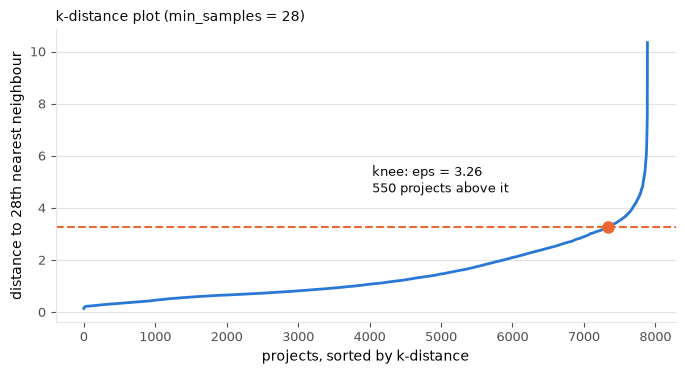

MIN_SAMPLES = 28, EPS = 3.26 (knee at the 93% point of the sorted curve)


In [9]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 2 * X.shape[1]

# kneighbors on the training data returns each point itself as neighbour 1 (distance 0),
# which matches DBSCAN counting the point itself towards min_samples.
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)
k_dist = np.sort(dist[:, -1])

x01 = np.linspace(0, 1, len(k_dist))
y01 = (k_dist - k_dist.min()) / (k_dist.max() - k_dist.min())
knee = int(np.argmax(x01 - y01))
EPS = round(float(k_dist[knee]), 2)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(len(k_dist)), k_dist, color=BLUE, linewidth=2)
ax.axhline(EPS, color=ORANGE, linestyle="--", linewidth=1.5)
ax.plot(knee, EPS, "o", color=ORANGE, markersize=8)
ax.annotate(f"knee: eps = {EPS}\n{len(k_dist) - knee:,} projects above it",
            (knee, EPS), xytext=(-170, 25), textcoords="offset points", fontsize=9, color=INK)
ax.set(xlabel="projects, sorted by k-distance", ylabel=f"distance to {MIN_SAMPLES}th nearest neighbour")
title(ax, f"k-distance plot (min_samples = {MIN_SAMPLES})")
style(ax)
save_fig(fig, "outliers_dbscan_kdistance")
plt.show()
print(f"MIN_SAMPLES = {MIN_SAMPLES}, EPS = {EPS} (knee at the {knee / len(k_dist):.0%} point of the sorted curve)")

### 4b. Fit and sensitivity to `eps`

`dbscan_labels` is reused in §10. The table shows how the result moves with `eps`, the 2025 inactive rate of the outliers, and the share of *went quiet* projects that get flagged (validation only; the population inactive rate is 47%).

In [10]:
def dbscan_labels(X, eps, min_samples):
    """DBSCAN cluster labels as a Series aligned to X; -1 = noise = outlier."""
    return pd.Series(DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X), index=X.index)


labels = dbscan_labels(X, EPS, MIN_SAMPLES)
flags = pd.DataFrame(index=X.index)          # one boolean column per method, filled in §4-5
flags["dbscan"] = labels.eq(-1)

rows = {}
for eps in sorted({2.0, 2.5, 3.0, EPS, 3.5, 4.0}):
    lab = labels if eps == EPS else dbscan_labels(X, eps, MIN_SAMPLES)
    rows[eps] = {"clusters": lab.max() + 1, **outlier_summary(lab.eq(-1), y, quiet)}
display(pd.DataFrame(rows).T.rename_axis("eps").round(2))
print(f"Chosen eps = {EPS}: {flags['dbscan'].sum()} outliers ({flags['dbscan'].mean():.1%}), "
      f"{labels.max() + 1} cluster(s); population inactive rate {y.mean():.2f}")

,clusters,outliers,% outliers,inactive rate (outliers),inactive rate (inliers),% of quiet projects flagged
eps,,,,,,
2.00,1.0,1384.0,17.54,0.21,0.53,7.62
2.50,1.0,732.0,9.28,0.16,0.51,2.94
3.00,1.0,287.0,3.64,0.19,0.49,1.54
3.26,1.0,148.0,1.88,0.20,0.48,0.94
3.50,1.0,75.0,0.95,0.15,0.48,0.33
4.00,1.0,33.0,0.42,0.21,0.48,0.20


Chosen eps = 3.26: 148 outliers (1.9%), 1 cluster(s); population inactive rate 0.47


### 4c. What kind of projects did DBSCAN flag?

Median standardized value of each feature (0 = population average, in standard deviations), outliers vs inliers. Positive = more activity than a typical project.

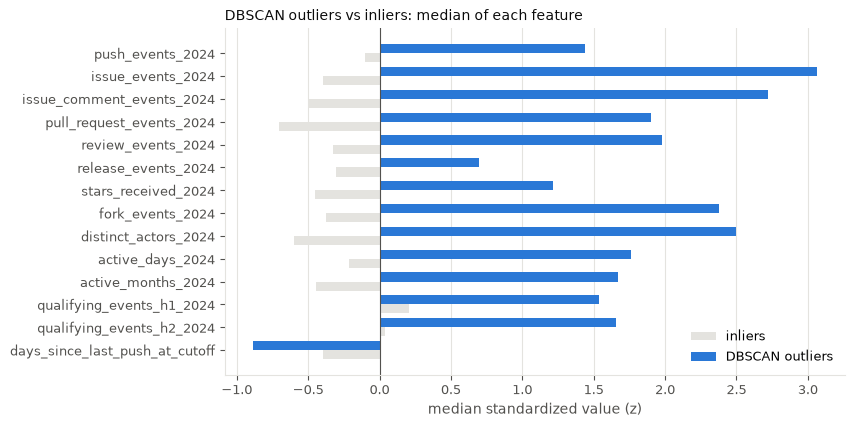

,inliers,DBSCAN outliers
push_events_2024,-0.10,1.44
issue_events_2024,-0.40,3.06
issue_comment_events_2024,-0.50,2.72
pull_request_events_2024,-0.71,1.90
review_events_2024,-0.33,1.98
release_events_2024,-0.30,0.69
stars_received_2024,-0.45,1.22
fork_events_2024,-0.38,2.37
distinct_actors_2024,-0.60,2.49
active_days_2024,-0.21,1.76


In [11]:
plot_profile(X, flags["dbscan"], "DBSCAN", "outliers_dbscan_profile")

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 1: DBSCAN, Lesson 11.4)
- **What it shows:**
  - **Parameters:** `min_samples` = 28 (2 × 14 features); `eps` = 3.26 from the knee of the k-distance plot, at the 93% point of the sorted curve.
  - **Result:** one dense cluster holding almost all real projects, plus **148 noise points (1.9%)** = DBSCAN outliers.
  - **Sensitivity:** the outlier count depends strongly on `eps` (≈ 1,400 at 2.0, ≈ 290 at 3.0, ≈ 75 at 3.5, ≈ 33 at 4.0), but there is always a single cluster and the outliers' inactive rate stays low (≈ 15–21%), so *which kind* of project is flagged does not depend on the exact `eps`.
  - **Who is flagged:** outliers are above the population median on **every** activity feature (issues, comments, forks, actors ≈ +2.5 to +3 SD), and their last push is more recent. They are **high-side** outliers: large, busy community projects (e.g. `websockets/ws`, `twostraws/ignite`, `membrane/api-gateway`) and some automation (`studio-arletti/uptime_monitor`).
  - **Validation:** only **20%** of DBSCAN outliers went inactive in 2025, vs 47% for the population.
  - **Key finding:** the 1,497 projects that went quiet in H2 (86% inactive in 2025) are almost never flagged (0.9%). **Decay is common, not rare** (1 in 5 real projects), so decaying projects form their own dense region; in a density-based method, common = normal.
- **Notes for the report:**
  - DBSCAN treats outliers as points in sparse regions; with `eps` at the k-distance knee it isolates about 2% of real projects.
  - Those outliers are exceptionally active, healthy projects (and some automation), not decaying ones. Decaying projects are too common to be outliers by density, which is itself a finding: decay is a *mode* of the data (a cluster), not an anomaly. This connects directly to the clustering section.
  - Together with §5 this led to the revised definition in §2f: outliers = abnormal activity; decay is a common pattern, not an outlier.


## 5. Method 2: One-Class SVM (Lesson 12.2, classification / boundary based)

**Question:** Which projects fall outside the learned boundary of a *normal* maintained project?

**Approach:**
- One-Class SVM learns a boundary around the bulk of the data without any labels; points outside it are outliers.
- RBF kernel (the boundary can be curved), `gamma="scale"`, `nu = 0.01` ≈ upper bound on the share of outliers (§2f).
- 7,890 rows is small enough to fit on the whole population.
- Decision-score histogram with the cutoff marked.
- The fit is wrapped in `ocsvm_outliers(X, nu)` so §10 can reuse it.

### 5a. Parameters and fit

- **Kernel = RBF:** the boundary around normal projects can be curved, not just a straight cut.
- **`nu` = 0.01:** upper bound on the share of training points left outside the boundary (and lower bound on the share of support vectors). It encodes our expectation that about 1% of real projects are outliers (§2f).
- **`gamma` = `"scale"`** = 1 / (n_features × Var(X)) = 1/14 ≈ 0.07, because `X` is standardized. It sets how far each point's influence reaches: larger `gamma` → tighter, wigglier boundary.
- 7,890 rows is small enough to fit on the whole population (under a second).
- The **decision score** is the signed distance to the boundary: negative = outside = outlier. `ocsvm_scores` is reused in §10.

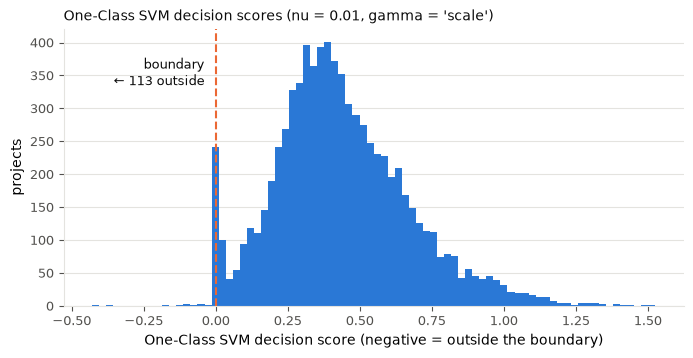

One-Class SVM: 113 outliers (1.4%); population inactive rate 0.47


In [12]:
from sklearn.svm import OneClassSVM

NU, GAMMA = 0.01, "scale"


def ocsvm_scores(X, nu=NU, gamma=GAMMA):
    """One-Class SVM decision scores aligned to X; negative = outside the learned boundary = outlier."""
    model = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X)
    return pd.Series(model.decision_function(X), index=X.index)


scores = ocsvm_scores(X)
flags["ocsvm"] = scores.lt(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(scores, bins=80, color=BLUE)
ax.axvline(0, color=ORANGE, linestyle="--", linewidth=1.5)
ax.annotate(f"boundary\n← {flags['ocsvm'].sum()} outside", (0, ax.get_ylim()[1] * 0.9),
            xytext=(-8, 0), textcoords="offset points", fontsize=9, color=INK, va="top", ha="right")
ax.set(xlabel="One-Class SVM decision score (negative = outside the boundary)", ylabel="projects")
title(ax, f"One-Class SVM decision scores (nu = {NU}, gamma = {GAMMA!r})")
style(ax)
save_fig(fig, "outliers_ocsvm_scores")
plt.show()
print(f"One-Class SVM: {flags['ocsvm'].sum()} outliers ({flags['ocsvm'].mean():.1%}); population inactive rate {y.mean():.2f}")

### 5b. Sensitivity to `nu` and `gamma`

`nu` should roughly control the share of outliers; `gamma` is the setting that most often goes wrong. If `gamma` is too large, the boundary wraps tightly around individual points and flags many projects whatever `nu` says (overfitting).

In [13]:
rows = []
for nu in [0.01, 0.02, 0.05]:
    for gamma in [0.01, GAMMA, 0.3]:
        s = scores if (nu, gamma) == (NU, GAMMA) else ocsvm_scores(X, nu, gamma)
        rows.append({"nu": nu, "gamma": gamma, **outlier_summary(s.lt(0), y, quiet)})
pd.DataFrame(rows).round(2)

,nu,gamma,outliers,% outliers,inactive rate (outliers),inactive rate (inliers),% of quiet projects flagged
0,0.01,0.01,80,1.01,0.19,0.48,0.33
1,0.01,scale,113,1.43,0.28,0.48,1.47
2,0.01,0.3,654,8.29,0.30,0.49,6.55
3,0.02,0.01,158,2.00,0.20,0.48,0.94
4,0.02,scale,166,2.10,0.27,0.48,1.80
5,0.02,0.3,660,8.37,0.29,0.49,6.88
6,0.05,0.01,395,5.01,0.25,0.49,3.01
7,0.05,scale,403,5.11,0.26,0.49,3.67
8,0.05,0.3,623,7.90,0.26,0.49,5.48


### 5c. What kind of projects did One-Class SVM flag?

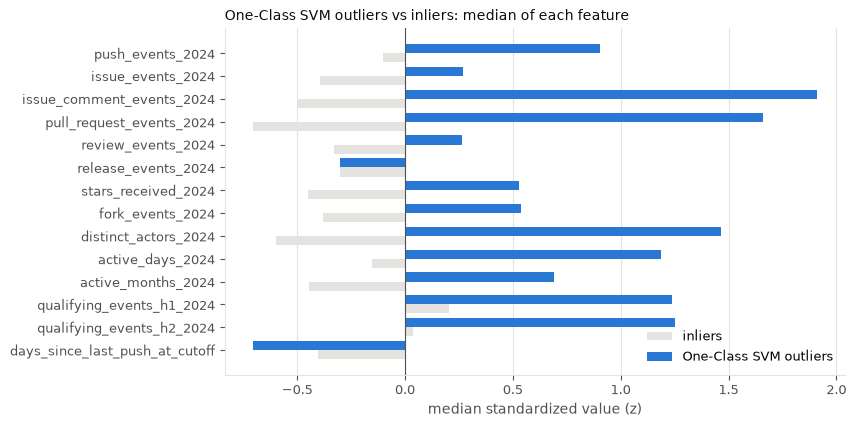

,inliers,One-Class SVM outliers
push_events_2024,-0.10,0.90
issue_events_2024,-0.40,0.27
issue_comment_events_2024,-0.50,1.91
pull_request_events_2024,-0.71,1.66
review_events_2024,-0.33,0.26
release_events_2024,-0.30,-0.30
stars_received_2024,-0.45,0.53
fork_events_2024,-0.38,0.54
distinct_actors_2024,-0.60,1.46
active_days_2024,-0.16,1.19


In [14]:
plot_profile(X, flags["ocsvm"], "One-Class SVM", "outliers_ocsvm_profile")

**Notes:**

- **Assignment item:** Outlier Detection → apply at least two methods (method 2: One-Class SVM, Lesson 12.2)
- **What it shows:**
  - **Parameters:** RBF kernel, `nu` = 0.01 (expected outlier share ≈ 1%), `gamma` = `"scale"` ≈ 0.07. Fit on all 7,890 projects in under a second.
  - **Result:** **113 outliers (1.4%)**, close to `nu`. The spike of ~170 projects just to the right of 0 in the score histogram are support vectors sitting on the boundary.
  - **Sensitivity:** with `gamma` ≤ `"scale"`, `nu` controls the share as intended (≈ 1%, 2%, 5%). With `gamma` = 0.3 about 8% are flagged **whatever `nu` is**: the boundary wraps individual points (overfitting). This justifies keeping `"scale"`.
  - **Who is flagged:** mostly above average (comments, PRs, contributors, active days ≈ +1.2 to +1.9 SD), but less extreme than DBSCAN's outliers. One-Class SVM flags **unusual combinations**, not only the biggest projects:
    - classroom / course repos with lots of activity but almost no pushes (`mate-academy/hibernate-configuration-hw`: 215 contributors, 264 PR events, 0 pushes; `cmu-17313q/nodebb`; `scothann/prpracticerepo`);
    - automation (`weiyilai/github-readme-stats`: 0 pushes, 116 active days);
    - very large projects also found by DBSCAN (`adguardteam/adguardfilters`, `navikt/pensjon-etterlatte-saksbehandling`);
    - a handful of low-side projects that stopped in H2 (`lvan-ni/applaudify`, `bergzeit/azure-sdk-for-go`).
  - **Validation:** 28% of outliers went inactive in 2025 (vs 47%); only 1.5% of the 1,497 went-quiet projects are flagged.
- **Notes for the report:**
  - One-Class SVM learns the boundary of normal projects without labels; projects outside it are outliers. `nu` sets the expected share; `gamma` sets how tight the boundary is, and too large a `gamma` overfits.
  - It confirms DBSCAN's main result with a different idea of "far": the outliers are mostly unusually active projects, and **decaying projects are inside the normal region**.
  - It also adds a different kind of outlier DBSCAN mostly missed: repos whose *mix* of activity is odd (many contributors and PRs but no pushes), typical of classroom assignments. These may be a **collective** outlier (many similar course repos).


## 6. Do the two methods agree, and what kinds of outliers are there?

**Question:** Which repos are outliers under both ideas of "far", and what *kinds* of abnormal activity do the outliers represent?

**Approach:**
- 2 × 2 overlap table and Jaccard similarity of the two flag sets.
- **Consensus outliers** = flagged by both methods (the strongest set, used in §7–9). **Any** = flagged by at least one (used to describe types).
- **Outlier types:** simple, explainable rules on the raw counts, checked in order (first match wins):
  1. **stopped in H2:** active in H1, H2 activity ≤ 10% of H1;
  2. **activity without pushes:** pushes < 20% of issue / comment / PR / review events (PR-driven or classroom repos);
  3. **automation / bulk pushes:** active ≥ 250 days with ≤ 2 contributors, *or* ≥ 500 pushes with almost no engagement (≤ 5% of pushes) and ≤ 5 contributors;
  4. **large community project:** ≥ 10 contributors or ≥ 500 engagement events;
  5. **new in H2 with a burst:** no H1 activity;
  6. **other mixed profile.**
- Which method finds which type, and 2025 inactivity per type (validation only).
- Example repos per type (input for §8).

### 6a. Agreement

In [15]:
flags["consensus"] = flags["dbscan"] & flags["ocsvm"]
flags["any"] = flags["dbscan"] | flags["ocsvm"]
jaccard = flags["consensus"].sum() / flags["any"].sum()

display(pd.crosstab(flags["dbscan"], flags["ocsvm"], rownames=["DBSCAN outlier"],
                    colnames=["One-Class SVM outlier"], margins=True, margins_name="total"))
print(f"Both: {flags['consensus'].sum()} | DBSCAN only: {(flags['dbscan'] & ~flags['ocsvm']).sum()} | "
      f"One-Class SVM only: {(flags['ocsvm'] & ~flags['dbscan']).sum()} | at least one: {flags['any'].sum()} | Jaccard = {jaccard:.2f}")
pd.DataFrame({m: outlier_summary(flags[m], y, quiet) for m in ["dbscan", "ocsvm", "consensus", "any"]}).T.round(2)

One-Class SVM outlier,False,True,total
DBSCAN outlier,,,
False,7681,61,7742
True,96,52,148
total,7777,113,7890


Both: 52 | DBSCAN only: 96 | One-Class SVM only: 61 | at least one: 209 | Jaccard = 0.25


,outliers,% outliers,inactive rate (outliers),inactive rate (inliers),% of quiet projects flagged
dbscan,148.0,1.88,0.20,0.48,0.94
ocsvm,113.0,1.43,0.28,0.48,1.47
consensus,52.0,0.66,0.21,0.48,0.40
any,209.0,2.65,0.24,0.48,2.00


### 6b. Outlier types

found_by,DBSCAN only,both,One-Class SVM only,total,inactive rate
type,,,,,
large community project,39,16,10,65,0.06
activity without pushes,21,17,17,55,0.13
automation / bulk pushes,12,2,7,21,0.10
new in H2 with a burst,5,2,5,12,0.42
stopped in H2,11,11,16,38,0.82
other mixed profile,8,4,6,18,0.06


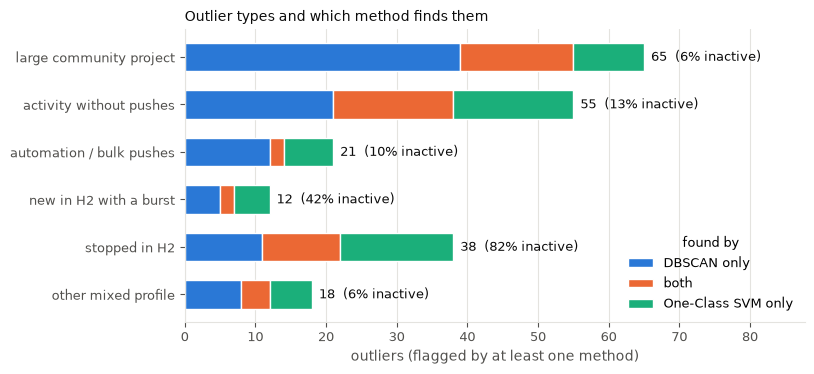

In [16]:
def outlier_type(df):
    """Rule-based type for each repo (first matching rule wins); thresholds are on raw 2024 counts."""
    push, actors, days = df["push_events_2024"], df["distinct_actors_2024"], df["active_days_2024"]
    eng = df[ENGAGEMENT].sum(axis=1)
    h1, h2 = df["qualifying_events_h1_2024"], df["qualifying_events_h2_2024"]
    rules = {
        "stopped in H2": (h1 > 0) & (h2 <= 0.1 * h1),
        "activity without pushes": push < 0.2 * (eng + 1),
        "automation / bulk pushes": ((days >= 250) & (actors <= 2)) | ((push >= 500) & (eng <= 0.05 * push) & (actors <= 5)),
        "large community project": (actors >= 10) | (eng >= 500),
        "new in H2 with a burst": h1 == 0,
    }
    return pd.Series(np.select(list(rules.values()), list(rules.keys()), default="other mixed profile"), index=df.index)


TYPE_ORDER = ["large community project", "activity without pushes", "automation / bulk pushes",
              "new in H2 with a burst", "stopped in H2", "other mixed profile"]
outliers = P[flags["any"]].assign(type=lambda d: pd.Categorical(outlier_type(d), TYPE_ORDER),
                                  found_by=np.select([flags["consensus"], flags["dbscan"]], ["both", "DBSCAN only"],
                                                     default="One-Class SVM only")[flags["any"]])
by_type = pd.crosstab(outliers["type"], outliers["found_by"])[["DBSCAN only", "both", "One-Class SVM only"]]
by_type["total"] = by_type.sum(axis=1)
by_type["inactive rate"] = outliers.groupby("type", observed=False)[LABEL].mean().round(2)
display(by_type)

fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(by_type))
for col, color in zip(["DBSCAN only", "both", "One-Class SVM only"], [BLUE, ORANGE, "#1baf7a"]):
    ax.barh(by_type.index, by_type[col], left=left, color=color, height=0.6, label=col,
            edgecolor="white", linewidth=1)
    left += by_type[col].to_numpy()
for yy, (total, rate) in enumerate(zip(by_type["total"], by_type["inactive rate"])):
    ax.text(total + 1, yy, f"{total}  ({rate:.0%} inactive)", va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(0, by_type["total"].max() * 1.35)
ax.set_xlabel("outliers (flagged by at least one method)", color=MUTED)
ax.legend(frameon=False, fontsize=9, loc="lower right", title="found by", title_fontsize=9)
title(ax, "Outlier types and which method finds them")
style(ax, grid="x")
save_fig(fig, "outliers_types_by_method")
plt.show()

### 6c. Example repos per type

The most extreme outliers of each type by One-Class SVM score (input for §8).

In [17]:
SHOW = ["repo_full_name", "found_by", "push_events_2024", "distinct_actors_2024", "active_days_2024",
        "qualifying_events_h1_2024", "qualifying_events_h2_2024", "stars_received_2024", LABEL]
examples = (outliers.assign(score=scores, engagement=outliers[ENGAGEMENT].sum(axis=1))
            .sort_values("score").groupby("type", observed=True).head(4)
            .sort_values(["type", "score"]))
examples[["type"] + SHOW[:3] + ["engagement"] + SHOW[3:]].set_index(["type", "repo_full_name"])

found_by  \
type                     repo_full_name                                                         
large community project  adguardteam/adguardfilters                                      both   
                         scothann/prpracticerepo                                         both   
                         navikt/pensjon-etterlatte-saksbehandling                        both   
                         soenneker/soenneker.cosmos.suite                                both   
activity without pushes  mate-academy/hibernate-configuration-hw                         both   
                         cmu-17313q/nodebb                                               both   
                         weiyilai/github-readme-stats                                    both   
                         manssur94/manssur-personal-tasks                                both   
automation / bulk pushes sslam1234/statslamgamedata                        One-Class SVM only   
                         tja4472/ngrx-task                                 One-Class SVM only   
                         rimim/duck_gym                                    One-Class SVM only   
                         fantasyworld123/rsshub                            One-Class SVM only   
new in H2 with a burst   avanade/approval-system                                         both   
                         vitonsky/arrival-time                             One-Class SVM only   
                         pjy02/v2ray-rules-dat                             One-Class SVM only   
                         pearl-image-comparer/pearl                                      both   
stopped in H2            open-sauced/api                                                 both   
                         animator/learn-python                                           both   
                         israfilalam22/custom_keycloak                     One-Class SVM only   
                         2lambda123/gping                                                both   
other mixed profile      cveproject/cvelist                                              both   
                         severecloud/arti                                  One-Class SVM only   
                         spring-financial-group/docker-credential-acr-env  One-Class SVM only   
                         arnesven/fatefuleight2                            One-Class SVM only   

                                                                           push_events_2024  \
type                     repo_full_name                                                       
large community project  adguardteam/adguardfilters                                   22260   
                         scothann/prpracticerepo                                        274   
                         navikt/pensjon-etterlatte-saksbehandling                      8478   
                         soenneker/soenneker.cosmos.suite                              3522   
activity without pushes  mate-academy/hibernate-configuration-hw                          0   
                         cmu-17313q/nodebb                                                2   
                         weiyilai/github-readme-stats                                     0   
                         manssur94/manssur-personal-tasks                                 0   
automation / bulk pushes sslam1234/statslamgamedata                                  362071   
                         tja4472/ngrx-task                                             1669   
                         rimim/duck_gym                                                8414   
                         fantasyworld123/rsshub                                         210   
new in H2 with a burst   avanade/approval-system                                        159   
                         vitonsky/arrival-time                                           50   
                         pjy02/v2ray-rules

**Notes:**

- **Assignment item:** Outlier Detection → compare methods; which repos are robustly anomalous; what kinds of outliers exist
- **What it shows:**
  - **Agreement:** 52 repos are flagged by both methods (consensus), 96 by DBSCAN only, 61 by One-Class SVM only; 209 by at least one. Jaccard = 0.25: the methods partly agree, as expected for two different ideas of "far" (sparse region vs outside a learned boundary).
  - **Types (209 outliers flagged by at least one method):**

    | type | outliers | DBSCAN | One-Class SVM | both | inactive in 2025 |
    |---|---|---|---|---|---|
    | large community project | 65 | 55 | 26 | 16 | 6% |
    | activity without pushes | 55 | 38 | 34 | 17 | 13% |
    | stopped in H2 | 38 | 22 | 27 | 11 | 82% |
    | automation / bulk pushes | 21 | 14 | 9 | 2 | 10% |
    | other mixed profile | 18 | 12 | 10 | 4 | 6% |
    | new in H2 with a burst | 12 | 7 | 7 | 2 | 42% |

  - **Which method finds what:** DBSCAN finds most large community projects (55 vs 26): they are extreme on many features at once, so they sit in sparse regions. One-Class SVM finds more "stopped in H2" projects (27 vs 22): a sharp H1→H2 drop is an unusual *combination* that falls outside the boundary even when no single value is extreme. Both find "activity without pushes" about equally (38 vs 34). Bulk-push automation is mostly found by one method or the other, rarely both (2).
  - **Validation:** every type except "stopped in H2" goes inactive far less often than the 47% base rate. "Stopped in H2" (82% inactive) is the only part of the original low-side hypothesis that survives: a small set of projects whose drop was sharp enough to be unusual.
  - **Collective outliers:** several automation outliers are generated repos with lorem-ipsum names (`erboladaiorg/deleniti-consequuntur-nostrum`, `taktikorg/doloremque-nemo`, `patrtorg/explicabo-atque-impedit`, ...), each with ~1,700 pushes, 2 contributors and no engagement — a farm of similar repos.
- **Notes for the report:**
  - Two methods with partial overlap; the 52 consensus outliers are the most reliable set.
  - Outliers are not one thing: they fall into a few interpretable types. Most are *healthy* (large or busy projects) or *not real maintenance* (automation, classroom activity); only one small type looks like decay.
  - The type rules are simple thresholds on raw counts so they can be explained in one sentence each; they describe the outliers, they do not detect them.


## 7. Visualizing the outliers and checking the definition

**Question:** What do the outliers look like compared with normal projects?

**Approach:**
- PCA 2-D scatter of `X`: inliers in grey, consensus outliers coloured by type.
- Key features (pushes, contributors, H1 vs H2 events, days since last push) for inliers vs each outlier type.
- 2025 inactivity by type next to the 47% base rate (validation only).

In [18]:
# TODO: PCA scatter with outliers highlighted

In [19]:
# TODO: feature comparison by group + inactive rate by group

**Notes:**

- **Assignment item:** Outlier Detection → visualize detected outliers and explain their characteristics
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 8. Potential causes

**Question:** Why are these repos outliers — real behaviour, automation, or data problems?

**Approach:**
- Read the names and profiles of the example outliers from §6c.
- Map each type to likely causes:
  - **large community project** → rare but valid;
  - **activity without pushes** → classroom / course repos, PR-driven workflows, mirrors;
  - **automation / bulk pushes** → bots, scrapers, generated or spam repos;
  - **new in H2 with a burst** → new project launch (valid) or bulk import;
  - **stopped in H2** → abandonment, finished project, or moved elsewhere;
  - any type → **data artifacts** (duplicate names, collection gaps).
- Count per cause.

In [20]:
# TODO: top outliers per side with names + assigned cause, counts per cause

**Notes:**

- **Assignment item:** Outlier Detection → discuss potential causes of these anomalies
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 9. Impact on clustering and dimensionality reduction

**Question:** If we keep vs remove the consensus outliers, do the clusters and the PCA picture change?

**Approach:**
- Baseline until teammates' settings are known: K-means (`K` by silhouette on `X`) and PCA, on the same `X`.
- Fit **with** and **without** consensus outliers and compare: PCA explained variance and loadings; cluster sizes, silhouette, centroid shift; Adjusted Rand Index on the shared inliers.
- Before / after figures.

In [21]:
# === Settings to replace with teammates' choices ===
K = None          # TODO: number of clusters (silhouette, or the clustering owner's k)
N_COMPONENTS = 2  # PCA components for plotting
# ====================================================
# TODO: fit K-means + PCA with / without consensus outliers, compare metrics

In [22]:
# TODO: before / after figures

**Notes:**

- **Assignment item:** Outlier Detection → evaluate the impact of outliers on clustering and dimensionality reduction
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 10. Robustness: a stricter population

**Question:** Does the result depend on where we drew the "real project" line?

**Approach:**
- Rerun the same pipeline on projects active ≥ 6 months (2,855 repos, 18% inactive): `build_features(real_projects(A, 6))` → `dbscan_outliers` / `ocsvm_outliers`.
- Compare: share of outliers, agreement, type mix, and whether decaying (went-quiet) projects are still inside the normal region.

In [23]:
# TODO: X6 = build_features(real_projects(A, 6)); rerun both methods; comparison table vs §6–7

**Notes:**

- **Assignment item:** (robustness, not required) does the outlier definition hold for a stricter population?
- **What it shows:** _TODO_
- **Notes for the report:** _TODO_


## 11. Summary for the report

Report-ready bullets for Section 3, plus inputs for Section 4 (integration, insights, limitations, next steps).

**Notes:** (filled in as sections are completed)

- **Population:** outliers are detected among **real projects**, repos active in ≥ 3 separate months of 2024 (7,890 repos, 12.6% of Table A, 47% inactive in 2025). The other 87% are one-burst repos (90% inactive) that were never maintained, so decay does not apply to them.
- **Outlier definition (§2f):** *hypothesis:* far from the consistently maintained middle in either direction (low side = decaying, high side = abnormal volume). *Revised after §4–5:* outliers are real projects with **abnormal activity** (very large, automated, odd mix); decay is common (1 in 5 real projects) and is a pattern for clustering, not an outlier.
- **Features:** 14 standardized 2024 activity features (log1p counts, H1 vs H2 events, days since last push). No package/Scorecard data, no 2025 label.
- **Method 1, DBSCAN:** `min_samples` = 28, `eps` = 3.26 from the k-distance knee → one dense cluster + 148 outliers (1.9%). All are high side: large, busy community projects and some automation. Only 20% went inactive in 2025 (vs 47%). Decaying projects (no H2 events, 1,497, 86% inactive) are almost never flagged (0.9%): **decay is common, so it is a mode of the data, not an anomaly.**
- **Method 2, One-Class SVM:** `nu` = 0.01, `gamma` = "scale" → 113 outliers (1.4%), 28% inactive in 2025. Confirms DBSCAN: mostly unusually active projects; only 1.5% of went-quiet projects flagged. Also flags odd *combinations* (classroom repos with many contributors and PRs but no pushes, automation). `gamma` too large (0.3) overfits: ~8% flagged regardless of `nu`.
- **Agreement and types:** 52 consensus outliers (flagged by both), 209 by at least one; Jaccard 0.25 (partial agreement, as expected for density vs boundary). Six rule-based types: large community projects (65, 6% inactive), activity without pushes / classroom (55, 13%), stopped in H2 (38, **82%**), automation / bulk pushes incl. a farm of lorem-ipsum repos (21, 10%), other (18), new in H2 with a burst (12, 42%). DBSCAN finds more large projects; One-Class SVM more sharp H1→H2 drops.
- **Characteristics and causes:** _TODO_
- **Validation (2025 inactivity by type):** all outliers 24% inactive vs 47% base rate; only the small "stopped in H2" type (38 repos, 82%) looks like decay — the part of the original low-side hypothesis that survives.
- **Impact on clustering / DR:** _TODO_
- **Robustness (≥ 6 months):** _TODO_
- **Actionable insight:** _TODO_
- **Limitations / next steps:** one-burst repos excluded by design; only two methods (GMM / VAE not run); packaged projects with deps.dev features not yet analysed; DBSCAN outlier count is sensitive to `eps` (the type of outlier is not); _TODO_
